# CineCue: 8. Does the day of the week matter? (context re-ranking)

Run notebooks 5 and 6 first. CineCue is meant to be *context-aware*. Notebook 5 found
that UTC submission time does not improve star predictions. This notebook asks the
matching question for **top-10 lists**:

> When a user comes back on a given weekday (and time of day), do the movies they liked on
> that same weekday, or the genres they lean towards on that weekday, predict what they
> will like that day better than the final ranker alone?

**Context features.** For each candidate movie, `src/cinecue/context.py` computes five
features:

| Feature | Meaning |
| --- | --- |
| `blend` | the final ranker's score (z-scored EASE + MF blend from notebook 6) |
| `same_weekday` | pull from only the likes made on the current weekday |
| `same_daypart` | the same, for likes made in the current six-hour UTC block |
| `weekday_genre` | how much *this user's* likes on this weekday lean to the movie's genres |
| `global_genre` | the same lean for *everyone's* ratings on this weekday |

A context re-ranker re-orders the final ranker's top 100 candidates by a weighted sum of
these features. The weights are learned by logistic regression.

**Protocol.** These are the same splits and settings as notebooks 5–6:

- An *event* is one user-day (UTC) on which a user known at the cutoff liked (4–5★) an
  unseen movie with 20+ ratings. The relevant movies are that day's liked ones.
- On **validation** (models fitted on train), each variant is scored by **5-fold
  cross-validation over users**.
- **Decision rule, fixed in advance:** a context variant replaces the final ranker only if
  its cross-validated gain has a 95% bootstrap interval above zero.
- On **test** (models refitted on train + validation), the validation weights are applied
  unchanged. The test split is used once, for reporting.

The cells below call the functions of `scripts/evaluate_context.py`, so the notebook and
the script compute exactly the same thing. The last cell checks that against
`results/context_summary.json`.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Work from either the repository root or its notebooks directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").is_file(), "Open this notebook from the cloned repository."
sys.path.insert(0, str(ROOT / "src"))
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

import time
import matplotlib.pyplot as plt
sys.path.insert(0, str(ROOT / "scripts"))
import evaluate_context as ec  # the experiment's functions, shared with the script
from cinecue.context import DAYPARTS, FEATURES, WEEKDAYS
from cinecue.data import load_movies, read_interactions, table_path
from cinecue.ranking import paired_bootstrap

processed = next(p for p in [ROOT / "data/processed", ROOT / "results"] if table_path(p, "train.csv").is_file())
splits = {name: read_interactions(table_path(processed, f"{name}.csv")) for name in ("train", "validation", "test")}
catalog = load_movies(processed).set_index("movie_id")
mf_settings = json.loads((processed / "rating_summary.json").read_text())["mf"]
selected = json.loads((processed / "ranking_summary.json").read_text())["selected"]
ALPHA, EASE_REG = float(selected["alpha"]), float(selected["ease_reg"])
print(f"Final ranker from notebook 6: EASE reg={EASE_REG:g}, alpha={ALPHA}; variants: {list(ec.VARIANTS)}")

Final ranker from notebook 6: EASE reg=30000, alpha=0.75; variants: ['final ranker', '+ same weekday', '+ same daypart', '+ weekday genres (user)', '+ weekday genres (everyone)', 'all context']


## Validation: build the events and their candidates

In [2]:
start = time.perf_counter()
train = splits["train"]
models = ec.fit_models(train, catalog, mf_settings, EASE_REG)
val_events = ec.find_events(splits["validation"], train, models)
val = ec.candidate_table(val_events, train, models, ALPHA)
val_users = len({row["user"] for row in val})
hit_rate = np.mean([row["y"].any() for row in val])
print(f"{len(val):,} validation user-day events from {val_users:,} users ({time.perf_counter() - start:.0f}s)")
print(f"Events with at least one liked movie among the final ranker's top {ec.DEPTH}: {hit_rate:.1%}")

888 validation user-day events from 491 users (47s)
Events with at least one liked movie among the final ranker's top 100: 62.7%


## Cross-validation over users

Users are split into five folds. Each fold's weights are learned on the other four folds and
scored on the held-out users, so no user is scored with weights fitted on their own events.

In [3]:
users = np.array(sorted({row["user"] for row in val}))
fold_of = dict(zip(users, np.random.default_rng(ec.SEED).permutation(len(users)) % ec.FOLDS))
cv, cv_users = {}, {}
for name, columns in ec.VARIANTS.items():
    scores = np.zeros(len(val))
    for fold in range(ec.FOLDS):
        fit_rows = [r for r in val if fold_of[r["user"]] != fold]
        held = [i for i, r in enumerate(val) if fold_of[r["user"]] == fold]
        scores[held] = ec.ndcg([val[i] for i in held], ec.fit_weights(fit_rows, columns), columns)
    cv_users[name] = ec.per_user(val, scores)
    cv[name] = float(cv_users[name].mean())
cv_gain = {name: paired_bootstrap(cv_users[name].to_numpy(), cv_users["final ranker"].to_numpy(), seed=ec.SEED)
           for name in ec.VARIANTS if name != "final ranker"}
cv_table = pd.DataFrame({"CV NDCG@10": cv}).join(pd.DataFrame(cv_gain).T.rename(
    columns={"difference": "gain vs final", "ci_low": "95% low", "ci_high": "95% high"}))
display(cv_table)
reliable = {name: cv[name] for name, gain in cv_gain.items() if gain["ci_low"] > 0}
BEST = max(reliable, key=reliable.get) if reliable else "final ranker"
display(Markdown(
    f"**Selected on validation: {BEST}.** "
    + (f"Its cross-validated gain over the final ranker is {cv_gain[BEST]['difference']:+.4f} NDCG@10 "
       f"(95% interval {cv_gain[BEST]['ci_low']:+.4f} to {cv_gain[BEST]['ci_high']:+.4f})."
       if BEST != "final ranker" else
       "No context variant has a gain whose 95% interval lies above zero, so the final ranker stays.")))

,CV NDCG@10,gain vs final,95% low,95% high
final ranker,0.1023,NaN,NaN,NaN
+ same weekday,0.1018,-0.0005,-0.0015,0.0005
+ same daypart,0.1017,-0.0006,-0.0021,0.0003
+ weekday genres (user),0.1015,-0.0008,-0.0030,0.0013
+ weekday genres (everyone),0.1019,-0.0004,-0.0009,0.0000
all context,0.1003,-0.0020,-0.0046,0.0002


**Selected on validation: final ranker.** No context variant has a gain whose 95% interval lies above zero, so the final ranker stays.

## Test: apply the validation weights unchanged

In [4]:
start = time.perf_counter()
history = pd.concat([train, splits["validation"]], ignore_index=True)
test_models = ec.fit_models(history, catalog, mf_settings, EASE_REG)
test = ec.candidate_table(ec.find_events(splits["test"], history, test_models), history, test_models, ALPHA)
print(f"{len(test):,} test user-day events from {len({r['user'] for r in test}):,} users "
      f"({time.perf_counter() - start:.0f}s)")
base = ec.per_user(test, ec.ndcg(test, np.array([1.0]), ["blend"]))
rows, weights_of = [], {}
for name, columns in ec.VARIANTS.items():
    weights = ec.fit_weights(val, columns)
    weights_of[name] = dict(zip(columns, map(float, weights)))
    ours = ec.per_user(test, ec.ndcg(test, weights, columns))
    row = {"variant": name, "validation CV NDCG@10": cv[name], "test NDCG@10": float(ours.mean())}
    if name != "final ranker":
        gain = paired_bootstrap(ours.to_numpy(), base.to_numpy(), seed=ec.SEED)
        row |= {"test gain": gain["difference"], "95% low": gain["ci_low"], "95% high": gain["ci_high"]}
    rows.append(row)
test_table = pd.DataFrame(rows).set_index("variant")
display(test_table)

7,593 test user-day events from 1,156 users (90s)


,validation CV NDCG@10,test NDCG@10,test gain,95% low,95% high
variant,,,,,
final ranker,0.1023,0.1003,NaN,NaN,NaN
+ same weekday,0.1018,0.1000,-0.0003,-0.0006,-0.0000
+ same daypart,0.1017,0.1002,-0.0001,-0.0004,0.0002
+ weekday genres (user),0.1015,0.0990,-0.0013,-0.0025,-0.0002
+ weekday genres (everyone),0.1019,0.1003,-0.0000,-0.0001,0.0000
all context,0.1003,0.0990,-0.0013,-0.0023,-0.0002


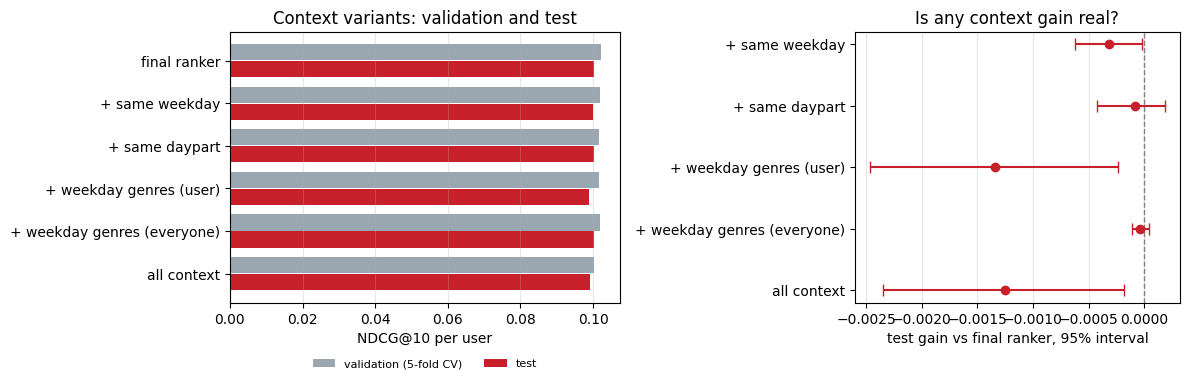

In [5]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.2, 1]})
names = list(test_table.index)
y = np.arange(len(names))
left.barh(y - 0.2, test_table["validation CV NDCG@10"], height=0.38, color="#9aa7b0", label="validation (5-fold CV)")
left.barh(y + 0.2, test_table["test NDCG@10"], height=0.38, color="#c8202a", label="test")
left.set(yticks=y, yticklabels=names, xlabel="NDCG@10 per user", title="Context variants: validation and test")
left.invert_yaxis()
left.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
gains = test_table.drop(index="final ranker")
gy = np.arange(len(gains))
right.errorbar(gains["test gain"], gy, xerr=[gains["test gain"] - gains["95% low"], gains["95% high"] - gains["test gain"]],
               fmt="o", color="#c8202a", capsize=4)
right.axvline(0, color="grey", lw=1, ls="--")
right.set(yticks=gy, yticklabels=gains.index, xlabel="test gain vs final ranker, 95% interval",
          title="Is any context gain real?")
right.invert_yaxis()
for axis in (left, right):
    axis.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

## What the re-ranker learned

The learned weights are the re-ranker's *feature importance*. Features are on comparable
scales, so a larger positive weight means the feature moves movies up more for the same
change in its value.

,blend,same_weekday,same_daypart,weekday_genre,global_genre
final ranker,1.000,–,–,–,–
+ same weekday,1.085,-0.034,–,–,–
+ same daypart,1.070,–,0.022,–,–
+ weekday genres (user),1.069,–,–,0.319,–
+ weekday genres (everyone),1.081,–,–,–,-0.041
all context,1.058,-0.040,0.035,0.318,-0.070


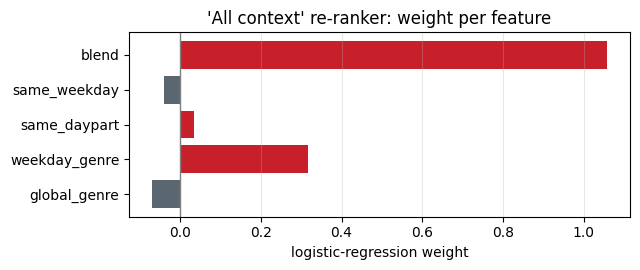

In [6]:
weights = pd.DataFrame(weights_of).T.reindex(columns=FEATURES)
display(weights.style.format("{:.3f}", na_rep="–"))
full = weights.loc["all context"]
fig, axis = plt.subplots(figsize=(6.5, 2.8))
axis.barh(full.index, full.values, color=["#c8202a" if v > 0 else "#5b6770" for v in full.values])
axis.axvline(0, color="grey", lw=1)
axis.set(xlabel="logistic-regression weight", title="'All context' re-ranker: weight per feature")
axis.invert_yaxis()
axis.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

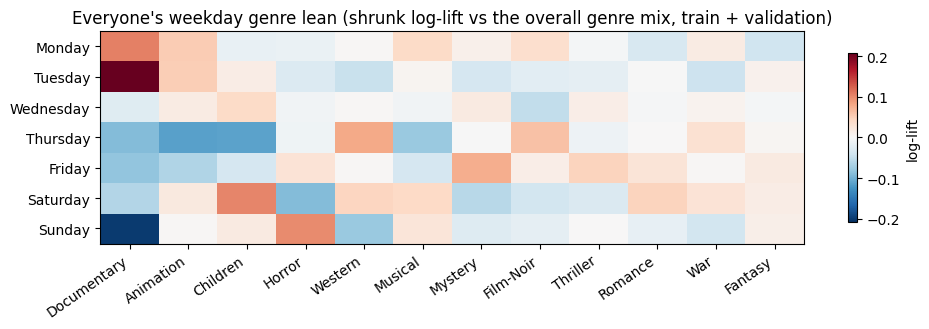

**Interpretation:** the largest weekday lean is Documentary on Tuesday: +23% relative to that genre's usual share (log-lift +0.209), in a small genre. A typical weekday-genre cell differs by only 2%. Rating activity shows modest weekday patterns, which the test results above show are too weak to improve individual top-10 lists.

In [7]:
lift = pd.DataFrame({WEEKDAYS[d]: {g: float(test_models["lift"][d, k]) for k, g in enumerate(test_models["vocabulary"])}
                     for d in range(7)}).T
top = lift.abs().max().sort_values(ascending=False).index[:12]
fig, axis = plt.subplots(figsize=(10, 3.4))
image = axis.imshow(lift[top].to_numpy(), cmap="RdBu_r", vmin=-lift[top].abs().max().max(), vmax=lift[top].abs().max().max(),
                    aspect="auto")
axis.set(xticks=range(len(top)), yticks=range(7), yticklabels=lift.index,
         title="Everyone's weekday genre lean (shrunk log-lift vs the overall genre mix, train + validation)")
axis.set_xticklabels(top, rotation=35, ha="right")
fig.colorbar(image, ax=axis, shrink=0.8, label="log-lift")
fig.tight_layout()
plt.show()
strongest = lift[top].stack().abs().idxmax()
typical = float(np.median(np.abs(np.expm1(lift.to_numpy()))))
display(Markdown(f"**Interpretation:** the largest weekday lean is {strongest[1]} on {strongest[0]}: "
                 f"{np.expm1(lift.loc[strongest]):+.0%} relative to that genre's usual share (log-lift "
                 f"{lift.loc[strongest]:+.3f}), in a small genre. A typical weekday-genre cell differs by only "
                 f"{typical:.0%}. Rating activity shows modest weekday patterns, which the test results above "
                 "show are too weak to improve individual top-10 lists."))

In [8]:
chosen = test_table.loc[BEST]
summary = json.loads((ROOT / "results/context_summary.json").read_text(encoding="utf-8"))
saved = {row["variant"]: row for row in summary["variants"]}
assert summary["selected"]["variant"] == BEST
for name in ec.VARIANTS:
    assert abs(saved[name]["validation_cv_ndcg"] - cv[name]) < 1e-9, name
    assert abs(saved[name]["test_ndcg"] - test_table.loc[name, "test NDCG@10"]) < 1e-9, name
print("Matches results/context_summary.json, which the website reads for its context weights.")
gain_rows = test_table.drop(index="final ranker")
reliable_on_test = gain_rows.index[gain_rows["95% low"] > 0].tolist()
display(Markdown(
    f"**Interpretation:** On test, the selected setting (**{BEST}**) scores NDCG@10 {chosen['test NDCG@10']:.4f}. "
    + ("No context variant has a test gain whose 95% interval lies above zero. " if not reliable_on_test else
       f"Variants with a test gain above zero: {', '.join(reliable_on_test)}. ")
    + "On MovieLens, knowing the weekday or time of day of past ratings does not reliably improve the next day's top 10. "
    "MovieLens records when people *rated*, in UTC and often in bursts, not when they watched. That is why the website "
    "keeps context as a choice (*Lean on this day's likes*), and why its own likes record the real local time: "
    "that is the data a future evaluation would need."))

Matches results/context_summary.json, which the website reads for its context weights.


**Interpretation:** On test, the selected setting (**final ranker**) scores NDCG@10 0.1003. No context variant has a test gain whose 95% interval lies above zero. On MovieLens, knowing the weekday or time of day of past ratings does not reliably improve the next day's top 10. MovieLens records when people *rated*, in UTC and often in bursts, not when they watched. That is why the website keeps context as a choice (*Lean on this day's likes*), and why its own likes record the real local time: that is the data a future evaluation would need.